<a href="https://colab.research.google.com/github/afifam24/-ResolveOps_Portfolio/blob/main/Day5_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
from sklearn.datasets import load_breast_cancer
dataset = load_breast_cancer(as_frame=True)
df=dataset.frame
print(df.shape)
df.head()


(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [9]:
df.shape

(569, 31)

In [4]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [7]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

X_temp = X_val
y_temp = y_val

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
baseline_model = LogisticRegression(max_iter=10000)
baseline_model.fit(X_train, y_train)
y_val_pred = baseline_model.predict(X_temp)
baseline_accuracy = accuracy_score(y_temp, y_val_pred)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Accuracy (%):", baseline_accuracy * 100)

Baseline Accuracy: 0.9473684210526315
Baseline Accuracy (%): 94.73684210526315


In [33]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


grid_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000)
)


param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}


grid_search = GridSearchCV(
    grid_pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)


grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'logisticregression__C': 1}
Best Cross-Validation Accuracy: 0.9799367088607595


In [49]:
best_model = grid_search.best_estimator_


y_val_tuned_pred = best_model.predict(X_temp)

tuned_accuracy = accuracy_score(y_temp, y_val_tuned_pred)

print("Tuned Model Validation Accuracy:", tuned_accuracy)
print("Tuned Model Validation Accuracy (%):", tuned_accuracy * 100)

Tuned Model Validation Accuracy: 0.9882352941176471
Tuned Model Validation Accuracy (%): 98.82352941176471


In [42]:
import pandas as pd
from sklearn.metrics import accuracy_score


pipe.fit(X_train, y_train)
y_pipe_pred = pipe.predict(X_temp)
pipeline_accuracy = accuracy_score(y_temp, y_pipe_pred)


comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "StandardScaler + Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "Validation Accuracy": [
        baseline_accuracy,
        pipeline_accuracy,
        tuned_accuracy
    ]
})

comparison["Accuracy (%)"] = comparison["Validation Accuracy"] * 100

display(comparison)

,Model,Validation Accuracy,Accuracy (%)
0,Baseline Logistic Regression,0.947368,94.736842
1,StandardScaler + Logistic Regression,0.988304,98.830409
2,Tuned Logistic Regression,0.988304,98.830409


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X, y = data.data, data.target


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)


X_temp = X_val
y_temp = y_val

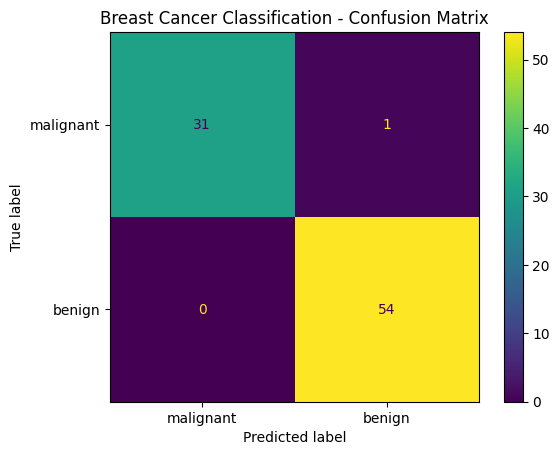

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


y_test_pred = best_model.predict(X_test)


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=data.target_names
)

plt.title("Breast Cancer Classification - Confusion Matrix")
plt.show()